### Download dataset from HuggingFace for offline usage

In [ ]:
# import pandas as pd
# from datasets import load_dataset

# try:
#     print("Downloading dataset from HuggingFace...")
#     # Load from the hub
#     dataset = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")
    
#     # Convert 'train' split to Pandas DataFrame
#     df_download = pd.DataFrame(dataset['train'])
    
#     # Save to local directory
#     df_download.to_csv("customer_support_data.csv", index=False)
    
#     print("Data saved as 'customer_support_data.csv'.")
    
# except Exception as e:
#     print(f"Error downloading data: {e}")

### Environment Setup & Library Import

Includes standard ML libraries and Deep Learning libraries.

In [1]:
# Data Manipulation & Visualization
import pandas as pd             # For handling tables (DataFrames)
import numpy as np              # For math operations
import matplotlib.pyplot as plt # For basic plotting
import seaborn as sns           # For pretty charts (Heatmaps, Bar charts)
import re                       # For Regular Expressions (text pattern matching)
import os                       # For operating system commands (checking files)
import shutil                   # For high-level file operations (deleting folders)

# Classical Natural Language Processing (NLP)
import nltk
from nltk.corpus import stopwords, wordnet    # Common words to ignore
from nltk.stem import WordNetLemmatizer       # Converts words to root form

# Machine Learning (SVM Baseline)
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer # Converts text to numbers
from sklearn.svm import LinearSVC                           # The SVM Algorithm
from sklearn.pipeline import Pipeline                       # Bundles steps together
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Deep Learning (BERT Model)
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, EarlyStoppingCallback
from datasets import Dataset

# Utilities
from spellchecker import SpellChecker # For the typo correction layer

# --- CONFIGURATION ---
pd.set_option('display.max_colwidth', 150) # Show full text in tables
sns.set(style='whitegrid')                 # Make charts look professional

# Automatic Hardware Acceleration
# Checks if an NVIDIA GPU is available. If yes, uses 'cuda' for speed.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Download necessary English language data
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print(f"Libraries and configurations loaded. Using device: {device}")

Libraries and configurations loaded. Using device: cuda


### Hardware Verification

This checks if PyTorch detects your NVIDIA GPU to enable fast training.

In [2]:
print(f"Is CUDA available? : {torch.cuda.is_available()}")
print(f"PyTorch Version    : {torch.__version__}")

if torch.cuda.is_available():
    # If True, it prints the name of your GPU (e.g., "GeForce GTX 1660 Ti")
    print(f"GPU Device         : {torch.cuda.get_device_name(0)}")
else:
    # If False, it means something went wrong with the installation
    print("You are currently running on CPU.")

Is CUDA available? : True
PyTorch Version    : 2.5.1+cu121
GPU Device         : NVIDIA GeForce GTX 1660 Ti


### Data Loading & Data Cleaning

Handles loading, renaming, duplicate removal, and "Culprit" (Leakage) removal.

In [3]:
# --- DATA PREPARATION ---

def load_and_clean_data():
    """
    Loads the CSV, standardizes column names, and handles structural errors.
    """
    file_path = "dataset/customer_support_data.csv"
    
    # Check if the file actually exists
    if not os.path.exists(file_path):
        raise FileNotFoundError("Please download the dataset.")
    
    print(f"Loading data from: {file_path}...")
    df = pd.read_csv(file_path)
    
    # 1. Rename columns: Standardize input to 'text' and label to 'category'
    if 'instruction' in df.columns:
        df = df.rename(columns={'instruction': 'text', 'intent': 'category'})
    
    # 2. Filter nulls: Remove empty rows that would crash the training
    df = df.dropna(subset=['text', 'category'])
    
    # 3. Remove duplicate columns: Fixes a specific Pandas error where columns appear twice
    df = df.loc[:, ~df.columns.duplicated()]
    
    return df

# --- NLP TOOLS SETUP ---
# Lemmatizer: Converts "shipping" -> "ship" (reduces complexity)
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Custom Stopwords: Remove polite words (e.g., "please", "hello") because
# they appear in every category and don't help distinguish intents.
domain_stopwords = stop_words.union({'please', 'hi', 'hello', 'thanks', 'im', 'would', 'could'})

def preprocess_text_svm(text):
    """
    Cleaning specific for the Baseline SVM model (Bag-of-Words approach).
    """
    text = str(text).lower()
    # Regex: Removes punctuation and numbers
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    
    # Remove stopwords and apply Lemmatization
    cleaned_words = [lemmatizer.lemmatize(w) for w in words if w not in domain_stopwords]
    
    # Sort words: This ensures "Order Return" and "Return Order" look identical
    # to the SVM model, improving accuracy for this specific algorithm.
    cleaned_words.sort()
    return " ".join(cleaned_words)

# --- EXECUTE ---
df = load_and_clean_data()

print("Preprocessing text for baseline...")
df['clean_text'] = df['text'].apply(preprocess_text_svm)

# --- LEAKAGE CONTROL ---
# Check if the category name (the answer) appears inside the text (the question).
# Example: If Category is "Refund" and text is "I want a refund", the model is cheating.
# Remove these rows to force the AI to learn patterns like "money back" instead.
df['culprit'] = df.apply(lambda r: str(r['category']).lower() in str(r['clean_text']).lower(), axis=1)

print(f"\nRemoving {df['culprit'].sum()} 'culprit' rows (potential leakage)...")
df = df[~df['culprit']].copy()

# Remove exact duplicate tickets to prevent overfitting
df.drop_duplicates(['clean_text'], inplace=True)
print(f"Final Dataset Shape: {df.shape}")

Loading data from: dataset/customer_support_data.csv...
Preprocessing text for baseline...

Removing 14162 'culprit' rows (potential leakage)...
Final Dataset Shape: (9343, 6)


### Exploratory Data Analysis (EDA)

It visualizes the data to check for Class Imbalance (are some categories too rare?) and Text Length (how long are the sentences?).

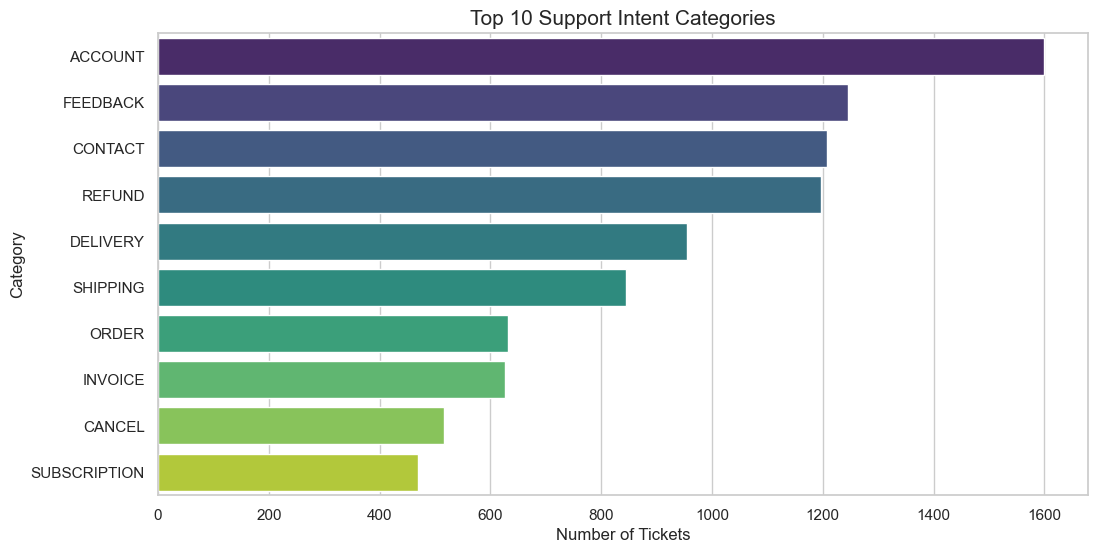

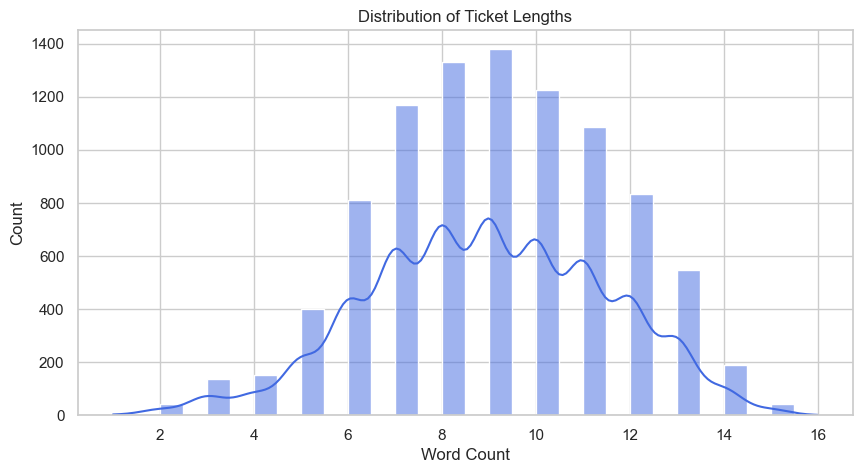

Average Ticket Length: 8.97 words


In [4]:
# --- EXPLORATORY DATA ANALYSIS (EDA) ---

# 1. Class Distribution Analysis
# Check if the dataset is balanced. If one category has very few examples,
# the model might struggle to learn it.
plt.figure(figsize=(12, 6))

# Calculate counts for each category
# .reset_index() converts the data into a standard DataFrame format
# to prevent errors with Seaborn plotting functions.
intent_counts = df['category'].value_counts().reset_index()
intent_counts.columns = ['Category', 'Count']

# Only plot the Top 10 to keep the chart readable
top_intents = intent_counts.head(10)

# Create a horizontal bar chart
sns.barplot(data=top_intents, x='Count', y='Category', palette='viridis')
plt.title('Top 10 Support Intent Categories', fontsize=15)
plt.xlabel('Number of Tickets')
plt.show()

# 2. Text Length Analysis
# Calculate how many words are in each ticket.
# This helps to decide on model parameters (e.g., how much text to read).
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
# Histplot shows the frequency distribution (Histogram + Density Curve)
sns.histplot(df['word_count'], bins=30, kde=True, color='royalblue')
plt.title('Distribution of Ticket Lengths')
plt.xlabel('Word Count')
plt.show()

# Print the average to get a quick summary statistic
print(f"Average Ticket Length: {df['word_count'].mean():.2f} words")

### Baseline Model (SVM)

Trains the SVM, optimizes hyperparameters, and runs advanced debugging.

In [5]:
# 1. Split Data
# X is the cleaned text, y is the category label.
X = df['clean_text']
y = df['category']

# Split 80% for training and 20% for testing.
# 'stratify=y' ensures that if 10% of data is "Refunds", 
# then 10% of both Train and Test sets will be "Refunds".
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7204, stratify=y
)

# 2. Pipeline Construction
# A Pipeline ensures the Vectorizer and Model are treated as one unit.
pipeline = Pipeline([
    # Step A: TF-IDF Vectorizer
    # Converts text to math. 'ngram_range=(1,2)' means it looks at individual words 
    # and pairs of words (e.g., "credit card") to capture context.
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2))),
    
    # Step B: LinearSVC (Support Vector Machine)
    # A fast, efficient algorithm standard for text classification tasks.
    ('clf', LinearSVC(random_state=7204, dual='auto'))
])

# 3. Hyperparameter Optimization (Grid Search)
print("Training Baseline Model...")

# Define a "Grid" of settings to test.
# 'C' controls how strictly the model fits the data (Regularization).
param_grid = {'clf__C': [0.1, 1, 10]}

# GridSearchCV trains the model 3 times for every setting to find the best average performance.
# n_jobs=-1 uses all CPU cores to speed up the process.
grid_search = GridSearchCV(pipeline, param_grid, cv=3, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Save the best version of the model
best_baseline = grid_search.best_estimator_
print(f"Best SVM Params: {grid_search.best_params_}")
print(f"SVM Accuracy: {grid_search.best_score_:.2%}")

# --- ADVANCED DEBUGGING ---
def debug_model_features(pipeline, model_name="Model"):
    """
    Extracts the most important words used by the model for decision making.
    This helps to verify the model isn't cheating (e.g., just looking for the word "refund").
    """
    feature_importance_df = pd.DataFrame({
        'feature': pipeline['tfidf'].get_feature_names_out(),
        'coefficient': pipeline['clf'].coef_[0] # Grabs weights for the first class
    })
    
    # Sort by absolute value (magnitude of importance)
    feature_importance_df['abs_coef'] = np.abs(feature_importance_df['coefficient'])
    top_feats = feature_importance_df.sort_values(by='abs_coef', ascending=False).head(5)
    
    print(f"\nTop Predictive Features for {model_name} (Class 0):")
    print(top_feats[['feature', 'coefficient']])

# Run the debug function
debug_model_features(best_baseline, "Baseline SVM")

y_pred_svm = best_baseline.predict(X_test)

# Print the full Classification Report for baseline model
print("--- SVM Classification Report ---")
print(classification_report(y_test, y_pred_svm))

Training Baseline Model...
Best SVM Params: {'clf__C': 10}
SVM Accuracy: 99.40%

Top Predictive Features for Baseline SVM (Class 0):
           feature  coefficient
4700        signup     3.918853
4944          user     3.504656
4447  registration     3.340700
4333       profile     2.734139
84         address    -2.398041
--- SVM Classification Report ---
              precision    recall  f1-score   support

     ACCOUNT       0.99      1.00      0.99       320
      CANCEL       1.00      1.00      1.00       103
     CONTACT       1.00      1.00      1.00       242
    DELIVERY       0.99      0.99      0.99       191
    FEEDBACK       1.00      1.00      1.00       249
     INVOICE       1.00      1.00      1.00       125
       ORDER       1.00      0.98      0.99       126
     PAYMENT       1.00      0.60      0.75        10
      REFUND       1.00      1.00      1.00       240
    SHIPPING       0.99      1.00      1.00       169
SUBSCRIPTION       1.00      1.00      1.00   

### Improvements (Deep Learning Prep)

Prepares data for DistilBERT and defines the Spell Checker.

In [6]:
# 1. Spell Checker Setup
# Initialize this here so can use it later during the live demo (Inference).
spell = SpellChecker()

def correct_spelling(text):
    """
    Identifies unknown words and replaces them with the most likely correct spelling.
    """
    words = text.split()
    misspelled = spell.unknown(words)
    # If word is misspelled, fix it; otherwise keep original.
    return " ".join([spell.correction(w) if w in misspelled and spell.correction(w) else w for w in words])

# 2. Prepare Data for BERT
# Deep Learning models require integer labels (0, 1, 2), not strings ("Refund", "Shipping").
unique_labels = sorted(df['category'].unique())
label2id = {label: i for i, label in enumerate(unique_labels)}
id2label = {i: label for i, label in enumerate(unique_labels)}

# Re-split Data
# Using the original 'df' with raw text, not 'clean_text'.
# BERT needs full context (grammar, stopwords) which removed for the SVM model.
df['label'] = df['category'].map(label2id)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=7204, stratify=df['category'])

# Convert Pandas DataFrames into HuggingFace Dataset objects
# This is the standard format required by the 'transformers' library.
hf_train = Dataset.from_pandas(train_df[['text', 'label']])
hf_test = Dataset.from_pandas(test_df[['text', 'label']])

# 3. Tokenization
# Load the DistilBERT tokenizer (a lighter, faster version of BERT).
model_ckpt = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

def tokenize(batch):
    # Padding=True: Adds zeros so all sentences are the same length.
    # Truncation=True: Cuts off sentences that are too long (max 512 tokens).
    return tokenizer(batch["text"], padding=True, truncation=True)

print("Tokenizing data for BERT...")
# Map the tokenizer function across the whole dataset
encoded_train = hf_train.map(tokenize, batched=True, batch_size=None)
encoded_test = hf_test.map(tokenize, batched=True, batch_size=None)

# Format for PyTorch
# Explicitly tell the dataset to output PyTorch tensors ('torch')
# containing only the columns the model actually needs for training.
encoded_train.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])
encoded_test.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])

print("Data Preparation Complete.")

Tokenizing data for BERT...


Data Preparation Complete.


### Fine-Tuning DistilBERT

Trains the Deep Learning model.

In [7]:
# Remove the old checkpoint folder to free space before starting
output_dir = f"{model_ckpt}-finetuned"
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)
    print(f"Cleaned up old checkpoints in {output_dir}")

# 1. Initialize Model
model = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt,
    num_labels=len(unique_labels),
    id2label=id2label,
    label2id=label2id
).to(device)

# 2. Define Metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="weighted")
    return {"accuracy": acc, "f1": f1}

# 3. Configure Optimized Training Rules
batch_size = 32

args = TrainingArguments(
    output_dir=output_dir,
    
    # --- OPTIMIZATION 1: SPEED ---
    fp16=True,                       # Uses Mixed Precision (2x speed on GTX 1660 Ti)
    num_train_epochs=10,             # Max epochs (Early stopping will likely cut this short)
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    
    # --- OPTIMIZATION 2: STORAGE MANAGEMENT ---
    save_strategy="epoch",           # Save at end of epoch
    eval_strategy="epoch",           # Check score at end of epoch
    save_total_limit=2,              # Only keep the 2 best checkpoints. Deletes others.
    load_best_model_at_end=True,     # Always load the best one when done
    metric_for_best_model="f1",      # Watch the F1 score to decide what is "best"
    greater_is_better=True,
    
    weight_decay=0.01,
    logging_steps=50,
    log_level="error",
    report_to="none"                 # Disable WandB (Weights & Biases)/Tensorboard logging for cleaner output
)

# 4. Initialize Trainer with Early Stopping
trainer = Trainer(
    model=model,
    args=args,
    compute_metrics=compute_metrics,
    train_dataset=encoded_train,
    eval_dataset=encoded_test,
    
    # --- OPTIMIZATION 3: EARLY STOPPING ---
    # If F1 score doesn't improve for 3 epochs in a row, STOP.
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

# 5. Start Training
print("Starting Optimized BERT Training (FP16 + Early Stopping)...")
trainer.train()

# 6. Save Final
save_directory = "my_support_model"
trainer.save_model(save_directory)
tokenizer.save_pretrained(save_directory)

print(f"Best Model saved to '{save_directory}'")
print(f"(Unused checkpoints in '{output_dir}' were automatically deleted)")

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting Optimized BERT Training (FP16 + Early Stopping)...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.099969,0.048638,0.993579,0.990933
2,0.020202,0.014891,0.998395,0.998338
3,0.004888,0.010516,0.998930,0.998917
4,0.003320,0.010357,0.998930,0.998917
5,0.002273,0.009006,0.998930,0.998917
6,0.001715,0.007911,0.998930,0.998917


Best Model saved to 'my_support_model'
(Unused checkpoints in 'distilbert-base-uncased-finetuned' were automatically deleted)


### Final Evaluation & Visualization

Predictions from the Trainer on the test set and plot confusion matrix heatmap.

Running final evaluation on Test Set...


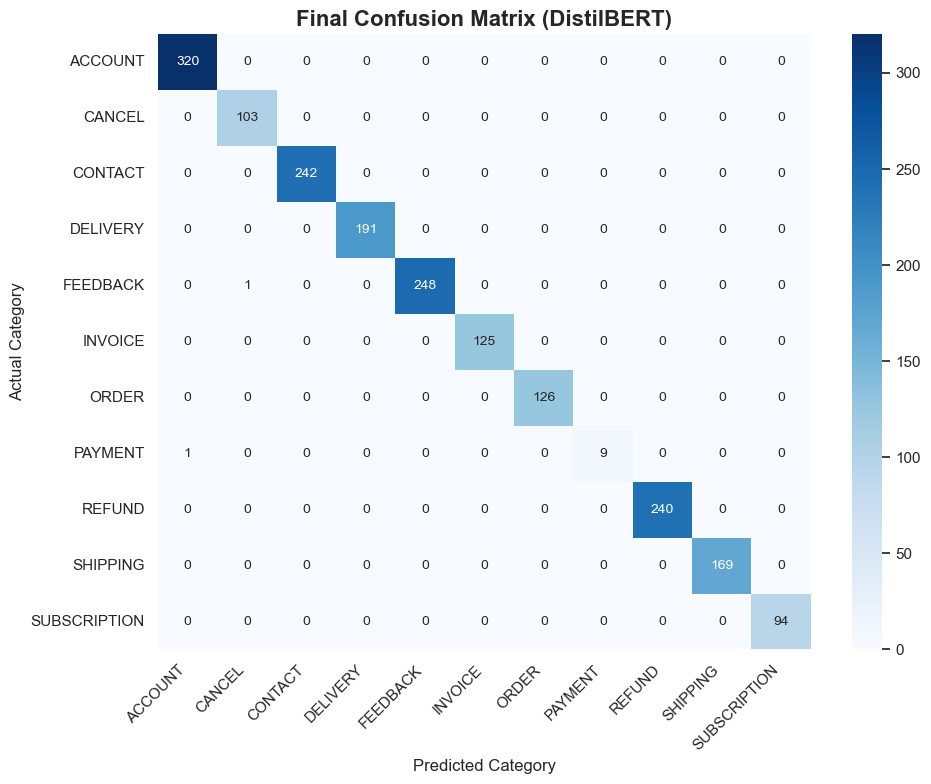


--- Final Classification Report ---
              precision    recall  f1-score   support

     ACCOUNT       1.00      1.00      1.00       320
      CANCEL       0.99      1.00      1.00       103
     CONTACT       1.00      1.00      1.00       242
    DELIVERY       1.00      1.00      1.00       191
    FEEDBACK       1.00      1.00      1.00       249
     INVOICE       1.00      1.00      1.00       125
       ORDER       1.00      1.00      1.00       126
     PAYMENT       1.00      0.90      0.95        10
      REFUND       1.00      1.00      1.00       240
    SHIPPING       1.00      1.00      1.00       169
SUBSCRIPTION       1.00      1.00      1.00        94

    accuracy                           1.00      1869
   macro avg       1.00      0.99      0.99      1869
weighted avg       1.00      1.00      1.00      1869



In [8]:
# 1. Make Predictions
print("Running final evaluation on Test Set...")
# The trainer runs the model on the test data to get raw scores (logits)
predictions_output = trainer.predict(encoded_test)

# 2. Extract Data
# The model gives probability scores for every category. 
# .argmax(-1) finds the index of the highest score (the "winner").
y_preds = predictions_output.predictions.argmax(-1)
y_true = predictions_output.label_ids # The correct answers

# 3. Create Confusion Matrix
# This counts: "How many times did we predict X when it was actually Y?"
cm = confusion_matrix(y_true, y_preds)

# 4. Prepare Labels for Plotting
# Convert numeric IDs (0, 1, 2) back to names ("Shipping", "Refund") for the chart
labels = [id2label[i] for i in range(len(unique_labels))]

# 5. Plot the Heatmap
plt.figure(figsize=(10, 8)) 

# Logic: If we have >20 categories, the chart gets too crowded.
# only plot the first 20 categories for clarity.
if len(labels) > 20:
    print("Dataset has many categories. Plotting top 20 for clarity...")
    sns.heatmap(cm[:20, :20], annot=True, fmt='d', cmap='Blues', 
                xticklabels=labels[:20], yticklabels=labels[:20],
                annot_kws={"size": 10}) 
else:
    # If fewer than 20, plot everything
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 10})

# Chart Styling
plt.title('Final Confusion Matrix (DistilBERT)', fontsize=16, fontweight='bold')
plt.ylabel('Actual Category', fontsize=12)
plt.xlabel('Predicted Category', fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Text Summary
# Prints the Precision, Recall, and F1 Score for every single category
print("\n--- Final Classification Report ---")
print(classification_report(y_true, y_preds, target_names=labels))

### Smart Inference

Combines Spell Check + BERT + Confidence Thresholding.

In [9]:
# A list of business-specific words. If a ticket doesn't contain any of these,
# Assume it is "Noise" or "Spam" and ignore it.
domain_keywords = [
    "order", "package", "item", "deliver", "ship", "return", "refund", 
    "account", "login", "pass", "invoice", "bill", "payment", "card", 
    "cancel", "change", "address", "broken", "damaged", "received", "status",
    "track", "credit", "charge", "help", "support", "website", "app"
]

def is_domain_relevant(text):
    """
    The 'Bouncer' Function:
    Checks if the user text is actually related to e-commerce business.
    Returns True if valid, False if irrelevant.
    """
    # Clean and split text
    text = str(text).lower()
    # Remove punctuation for cleaner matching
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    
    for word in words:
        for key in domain_keywords:
            # 1. Exact match (e.g., user types "app" and keyword is "app")
            if word == key:
                return True
            # 2. Root match (e.g., keyword "ship" matches user word "shipping")
            # Skip very short keys to avoid false positives (e.g., "ap" matching "apple")
            if len(key) > 3 and word.startswith(key):
                return True
                
    return False

def smart_predict(text, threshold=0.70):
    """
    The Master Function:
    Orchestrates the entire flow: Safety -> Cleaning -> AI -> Risk Management.
    """
    
    # 1. GUARDRAIL CHECK (Safety)
    # If the text has nothing to do with e-commerce, stop immediately.
    if not is_domain_relevant(text):
        return "⛔ Irrelevant / Off-Topic", 0.0, text

    # 2. SPELL CHECK (Cleaning)
    # Fixes typos so the AI understands better (e.g., "shippng" -> "shipping")
    clean_text = correct_spelling(text)
    
    # 3. BERT PREDICTION (The Brain)
    # Convert text to tensor and feed into GPU model
    inputs = tokenizer(clean_text, return_tensors="pt", truncation=True).to(device)
    
    with torch.no_grad(): # Disable gradient calculation for faster inference
        outputs = model(**inputs)
    
    # 4. PROBABILITY CALCULATION
    # Convert raw output (logits) to percentages (0.0 to 1.0)
    probs = F.softmax(outputs.logits, dim=-1)
    max_prob, predicted_id = torch.max(probs, dim=-1)
    
    score = max_prob.item()
    label = id2label[predicted_id.item()]
    
    # 5. THRESHOLD CHECK (Risk Management)
    # If the AI is not at least 70% sure, don't auto-route it. Send to human team for review.
    if score < threshold:
        return f"⚠️ Human Queue (Low Conf)", score, clean_text
    else:
        return f"✅ {label}", score, clean_text

# --- LIVE DEMO ---
new_tickets = [
    "I want to rturn my damaged item.",                     # Case 1: Typo ('rturn') + Valid Intent
    "Where is my package?",                                 # Case 2: Perfect Valid Intent
    "How is the weather?",                                  # Case 3: Irrelevant (Should be blocked)
    "This is a Text Classification module.",                # Case 4: Irrelevant (Should be blocked)
    "My login passwrd is broken.",                          # Case 5: Typo ('passwrd') + Valid Intent
    "I heve a qustien abut the order bt FeelsBadMan."       # Case 6: Mentioning 'order' passes the guardrail, but the rest is gibberish/vague
]

print("--- AUTO-TRIAGE SYSTEM LIVE DEMO ---")
print(f"Confidence Threshold: 70%\n")

for ticket in new_tickets:
    route, conf, corrected = smart_predict(ticket)
    
    print(f"Input:     '{ticket}'")
    
    # Display logic
    if route.startswith("⛔"):
        print(f"Route:      {route}") # Irrelevant
    else:
        print(f"Corrected: '{corrected}'") # Show how spell checker fixed it
        print(f"Route:      {route} (Conf: {conf:.2%})") # Show AI decision
    
    print("-" * 50)

--- AUTO-TRIAGE SYSTEM LIVE DEMO ---
Confidence Threshold: 70%

Input:     'I want to rturn my damaged item.'
Corrected: 'I want to turn my damaged item'
Route:      ⚠️ Human Queue (Low Conf) (Conf: 59.01%)
--------------------------------------------------
Input:     'Where is my package?'
Corrected: 'Where is my package'
Route:      ✅ DELIVERY (Conf: 74.84%)
--------------------------------------------------
Input:     'How is the weather?'
Route:      ⛔ Irrelevant / Off-Topic
--------------------------------------------------
Input:     'This is a Text Classification module.'
Route:      ⛔ Irrelevant / Off-Topic
--------------------------------------------------
Input:     'My login passwrd is broken.'
Corrected: 'My login password is broken'
Route:      ✅ ACCOUNT (Conf: 99.78%)
--------------------------------------------------
Input:     'I heve a qustien abut the order bt FeelsBadMan.'
Corrected: 'I have a question abut the order bt FeelsBadMan.'
Route:      ⚠️ Human Queue (Low C